# Notebook 3: Resultater 

In [159]:
# Importerer nødvendige libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from openpyxl.styles import Alignment
import os

### Leser inn resultatene fra LR og LLM

In [160]:
# Leser inn resultatene fra den logistiske regresjonsmodellen og LLM-en
lr_df = pd.read_csv('resultater_lr.csv')
llm_df = pd.read_csv('llm_test.csv')

In [161]:
# Kobler svarene sammen via klage-ID og tar med fasiten fra begge filene
resultater_df = lr_df.merge(llm_df[['Complaint ID', 'Issue', 'svar_llm']], on='Complaint ID', suffixes=('', '_llm'))

# Sjekker at hver klage finnes nøyaktig én gang i begge tabellene, og at fasiten er lik
assert len(resultater_df) == len(lr_df) == len(llm_df)
assert (resultater_df['Issue'] == resultater_df['Issue_llm']).all()
print('Koblingen er OK:', len(resultater_df), 'klager fra både LR og LLM, med lik fasit')

Koblingen er OK: 3583 klager fra både LR og LLM, med lik fasit


In [162]:
# Lager en alfabetisk sortert liste over alle unike klagekategorier
kategorier = sorted(resultater_df['Issue'].unique())

### Samlet ytelse

In [163]:
# Lager en ordbok som kobler navnet på hver metode til kolonnen som inneholder prediksjonene
metoder = {
    'Baseline': 'baseline',
    'Logistisk regresjon': 'lr_pred',
    'LLM (prompt B)': 'svar_llm',
}

# Lager en tabell
# Beregner accuracy og makro-F1 for hver metode ved å sammenligne prediksjonene med de faktiske kategoriene
sammenligning_df = pd.DataFrame({
    navn: {
        'Accuracy': accuracy_score(resultater_df['Issue'], resultater_df[kolonne]),
        'Makro-F1': f1_score(resultater_df['Issue'], resultater_df[kolonne], average='macro', zero_division=0),
    }
    for navn, kolonne in metoder.items()
}).T.round(2) # Snur tabellen slik at hver metode blir en rad, og runder av til to desimaler

# Skriver ut sammenligningstabellen
print(sammenligning_df)

                     Accuracy  Makro-F1
Baseline                 0.26      0.06
Logistisk regresjon      0.71      0.69
LLM (prompt B)           0.72      0.72


#### Paired bootstrap:

In [164]:
# Lager en tilfeldighetsgenerator med fast startverdi slik at resultatet kan gjenskapes
rng = np.random.default_rng(1)

# Beregner forskjellen i makro-F1 mellom LLM-en og LR for et utvalg klager
def forskjell_f1(df):
    return (f1_score(df['Issue'], df['svar_llm'], average='macro', zero_division=0)
            - f1_score(df['Issue'], df['lr_pred'], average='macro', zero_division=0))

# Trekker 1000 utvalg med tilbakelegging og beregner forskjellen i hvert av dem
n = len(resultater_df)
forskjeller = np.array([forskjell_f1(resultater_df.iloc[rng.integers(0, n, n)]) for _ in range(1000)])

# Skriver ut 95 % konfidensintervall og andelen trekninger der LLM-en ikke var bedre enn LR
andel = (forskjeller <= 0).mean()
print('95 % konfidensintervall for forskjellen i makro-F1:', np.percentile(forskjeller, [2.5, 97.5]).round(3))
print('Andel trekninger der LLM ikke var bedre:', '< 0.001' if andel == 0 else andel)

95 % konfidensintervall for forskjellen i makro-F1: [0.01  0.041]
Andel trekninger der LLM ikke var bedre: < 0.001


### Ytelse per kategori

In [165]:
# Lager en tabell som beregner F1 for hver kategori for begge modellene
f1_per_kategori_df = pd.DataFrame({
    'Logistisk regresjon': f1_score(resultater_df['Issue'], resultater_df['lr_pred'], labels=kategorier, average=None, zero_division=0),
    'LLM (prompt B)': f1_score(resultater_df['Issue'], resultater_df['svar_llm'], labels=kategorier, average=None, zero_division=0),
}, index=kategorier).round(2) 

# Lager en ny kolonne som viser hvor mye bedre eller dårligere LLM-en er enn LR for hver kategori
f1_per_kategori_df['Forskjell'] = (f1_per_kategori_df['LLM (prompt B)'] - f1_per_kategori_df['Logistisk regresjon']).round(2)

# Sorterer tabellen fra størst til minst forskjell, og skriver den ut
print(f1_per_kategori_df.sort_values('Forskjell', ascending=False))

                                                    Logistisk regresjon  \
Closing your account                                               0.68   
Advertising and marketing, including promotiona...                 0.61   
Getting a credit card                                              0.74   
Other features, terms, or problems                                 0.52   
Problem with a purchase shown on your statement                    0.84   
Fees or interest                                                   0.73   
Problem when making payments                                       0.73   

                                                    LLM (prompt B)  Forskjell  
Closing your account                                          0.79       0.11  
Advertising and marketing, including promotiona...            0.68       0.07  
Getting a credit card                                         0.80       0.06  
Other features, terms, or problems                            0.54       0.02  

### Forvekslinger

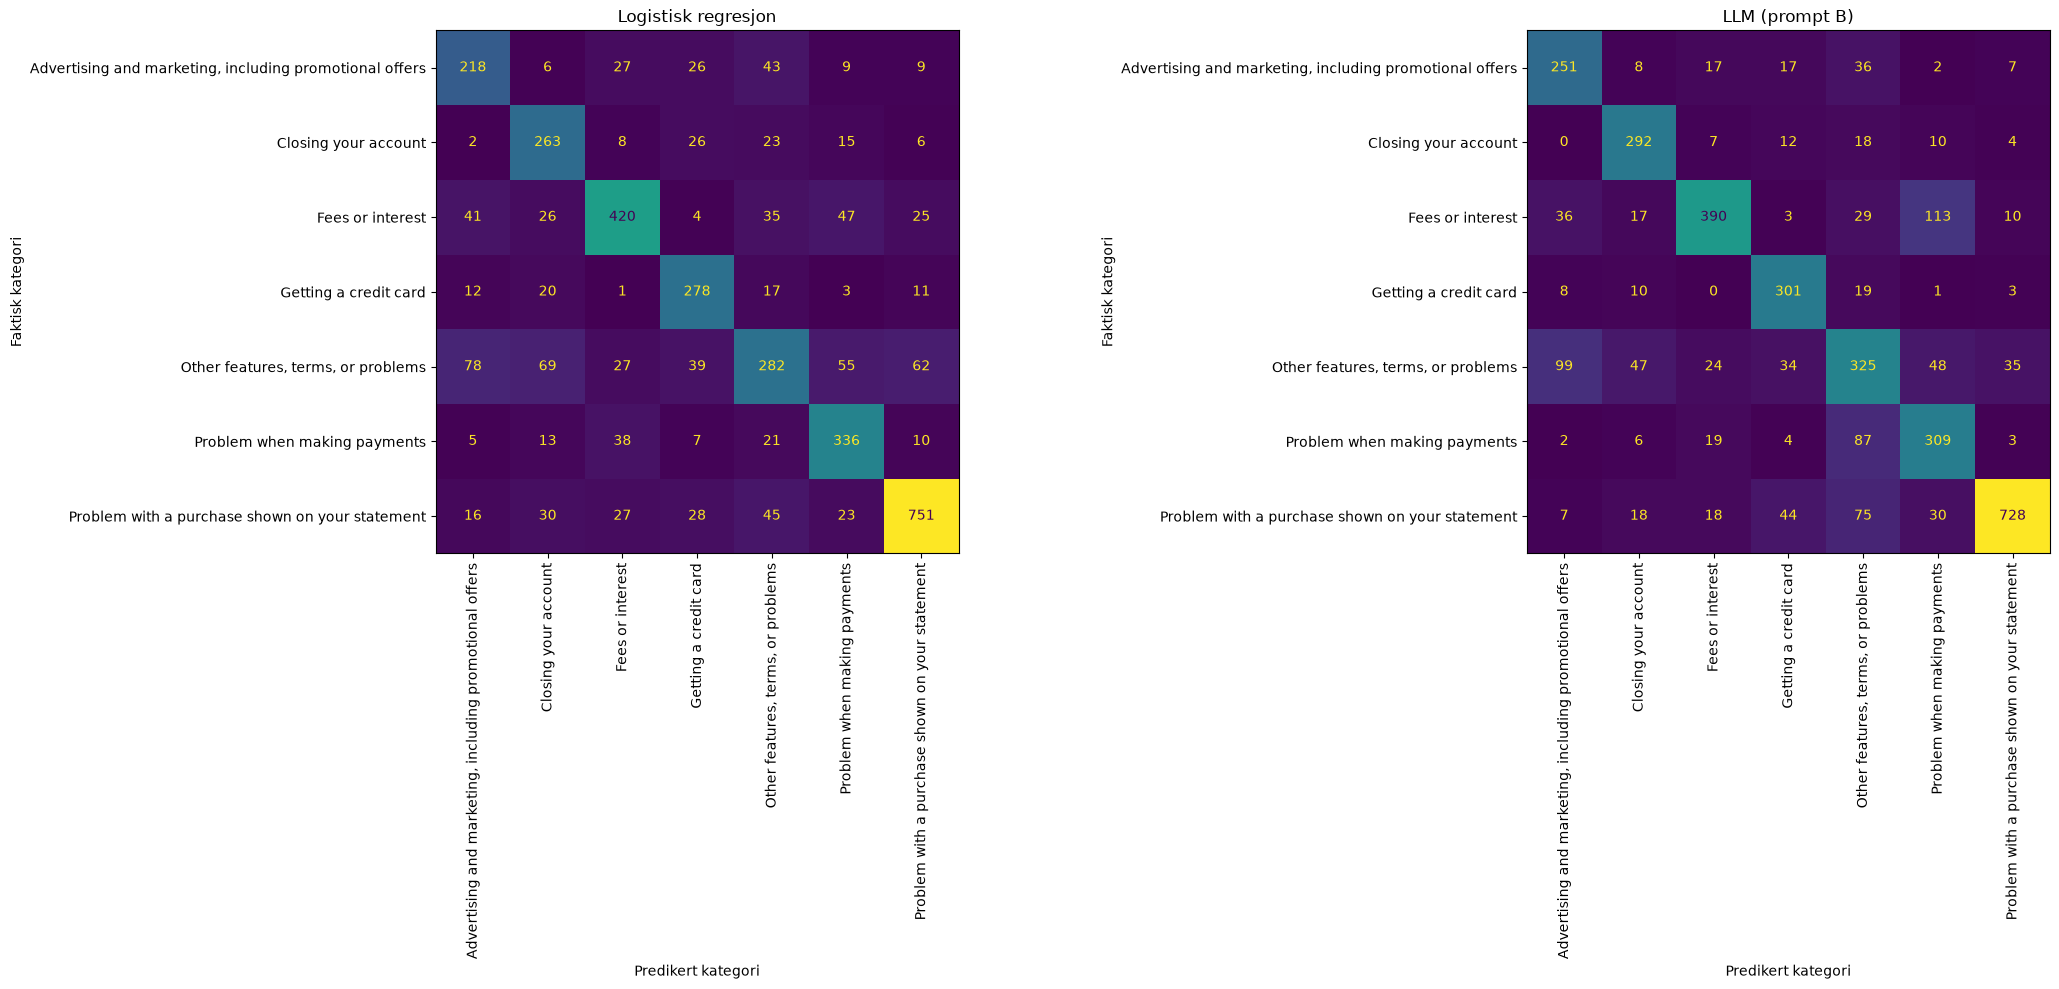

In [166]:
# Lager en figur med forvekslingsmatrisene for LR og LLM
fig, axes = plt.subplots(1, 2, figsize=(22, 10))

for ax, (navn, kolonne) in zip(axes, [('Logistisk regresjon', 'lr_pred'), ('LLM (prompt B)', 'svar_llm')]):
    ConfusionMatrixDisplay.from_predictions(
        resultater_df['Issue'], resultater_df[kolonne], labels=kategorier,
        xticks_rotation=90, ax=ax, colorbar=False
    )
    ax.set_title(navn)
    ax.set_xlabel('Predikert kategori')
    ax.set_ylabel('Faktisk kategori')

plt.tight_layout()
plt.savefig('forvekslingsmatriser.png', bbox_inches='tight', dpi=200)
plt.show()

### Enighet mellom modellene

In [167]:
# Lager en krysstabell som viser hvor ofte modellene tar riktig og galt på de samme klagene
resultater_df['lr_riktig'] = resultater_df['lr_pred'] == resultater_df['Issue']
resultater_df['llm_riktig'] = resultater_df['svar_llm'] == resultater_df['Issue']

print(pd.crosstab(resultater_df['lr_riktig'], resultater_df['llm_riktig'], rownames=['LR riktig'], colnames=['LLM riktig']))

LLM riktig  False  True 
LR riktig               
False         646    389
True          341   2207


In [168]:
# Henter ut klagene der både LR og LLM-en predikerte feil
begge_feil_df = resultater_df[~resultater_df['lr_riktig'] & ~resultater_df['llm_riktig']].copy()

# Markerer om de to modellene valgte den samme gale kategorien
begge_feil_df['samme_feil'] = begge_feil_df['lr_pred'] == begge_feil_df['svar_llm']

# Teller hvor ofte modellene tok feil på samme måte og på ulik måte
print(begge_feil_df['samme_feil'].value_counts())

samme_feil
True     459
False    187
Name: count, dtype: int64


### Klagelengde

In [169]:
# Teller antall ord i hver klage
resultater_df['antall_ord'] = resultater_df['Consumer complaint narrative'].str.split().str.len()

# Deler klagene i fire like store grupper etter lengde
resultater_df['lengdegruppe'] = pd.qcut(resultater_df['antall_ord'].rank(method='first'), 4,
                                        labels=['Korteste 25 %', '25–50 %', '50–75 %', 'Lengste 25 %'])

# Finner minste og største antall ord, og antall klager i hver kvartil
ord_per_gruppe_df = resultater_df.groupby('lengdegruppe', observed=True)['antall_ord'].agg(
    min_ord='min', maks_ord='max', antall_klager='count'
)

# Beregner makro-F1 for hver modell i hver kvartil
makro_f1_lengde_df = resultater_df.groupby('lengdegruppe', observed=True).apply(
    lambda gruppe: pd.Series({
        'LR': f1_score(gruppe['Issue'], gruppe['lr_pred'], average='macro', zero_division=0),
        'LLM': f1_score(gruppe['Issue'], gruppe['svar_llm'], average='macro', zero_division=0),
    })
).round(2)

print(ord_per_gruppe_df.join(makro_f1_lengde_df))

               min_ord  maks_ord  antall_klager    LR   LLM
lengdegruppe                                               
Korteste 25 %        4       106            896  0.71  0.72
25–50 %            106       186            896  0.70  0.75
50–75 %            186       308            895  0.67  0.69
Lengste 25 %       308      5735            896  0.66  0.71


In [170]:
# Beregner F1 for hver kategori i hver lengdegruppe for begge modellene
f1_kategori_lengde_df = resultater_df.groupby('lengdegruppe', observed=True).apply(
    lambda gruppe: pd.DataFrame({
        'LR': f1_score(gruppe['Issue'], gruppe['lr_pred'], labels=kategorier, average=None, zero_division=0),
        'LLM': f1_score(gruppe['Issue'], gruppe['svar_llm'], labels=kategorier, average=None, zero_division=0),
    }, index=kategorier)
).round(2)

# Viser én kolonne per lengdegruppe for hver modell
print(f1_kategori_lengde_df.unstack(level=0))

                                                              LR          \
lengdegruppe                                       Korteste 25 % 25–50 %   
Advertising and marketing, including promotiona...          0.42    0.67   
Closing your account                                        0.73    0.70   
Fees or interest                                            0.77    0.74   
Getting a credit card                                       0.79    0.74   
Other features, terms, or problems                          0.59    0.50   
Problem when making payments                                0.86    0.69   
Problem with a purchase shown on your statement             0.79    0.83   

                                                                         \
lengdegruppe                                       50–75 % Lengste 25 %   
Advertising and marketing, including promotiona...    0.60         0.68   
Closing your account                                  0.66         0.63   
Fees or interes

### Utvalg til manuell feilanalyse

In [171]:
# Deler klagene der minst én modell tok feil inn i tre grupper
grupper = {
    'Begge feil': resultater_df[~resultater_df['lr_riktig'] & ~resultater_df['llm_riktig']],
    'Bare LLM feil': resultater_df[resultater_df['lr_riktig'] & ~resultater_df['llm_riktig']],
    'Bare LR feil': resultater_df[~resultater_df['lr_riktig'] & resultater_df['llm_riktig']],
}

# Trekker 20 tilfeldige klager fra hver gruppe og markerer hvilken gruppe de kommer fra
feilanalyse_df = pd.concat(
    [df.sample(20, random_state=1).assign(gruppe=navn) for navn, df in grupper.items()]
)[['gruppe', 'Complaint ID', 'Issue', 'lr_pred', 'svar_llm', 'Consumer complaint narrative']].copy()

# Legger til en tom kolonne for å kategorisere hver feil manuelt
feilanalyse_df['feiltype'] = ''

# Filnavnet til Excel-filen for den manuelle feilanalysen
filnavn = 'manuell_feilanalyse.xlsx'

# Lagrer utvalget bare hvis filen ikke finnes fra før, slik at en utfylt fil ikke blir overskrevet
if os.path.exists(filnavn):
    print(filnavn, 'finnes allerede – hopper over lagring for ikke å overskrive')
else:
    # Lagrer utvalget som en Excel-fil med ryddig formatering for manuell gjennomgang
    with pd.ExcelWriter(filnavn, engine='openpyxl') as writer:
        feilanalyse_df.to_excel(writer, index=False, sheet_name='Feilanalyse')
        ark = writer.sheets['Feilanalyse']

        # Setter kolonnebredder: gruppe, ID, fasit, LR, LLM, klagetekst, feiltype
        for kolonne, bredde in zip('ABCDEFG', [16, 12, 28, 28, 28, 90, 22]):
            ark.column_dimensions[kolonne].width = bredde

        # Bryter teksten i alle celler og plasserer den øverst i cellen
        for rad in ark.iter_rows():
            for celle in rad:
                celle.alignment = Alignment(wrap_text=True, vertical='top')

        # Fryser overskriftsraden så den alltid er synlig når du blar
        ark.freeze_panes = 'A2'

    print('Lagret', filnavn)

manuell_feilanalyse.xlsx finnes allerede – hopper over lagring for ikke å overskrive
